# Пример. Классификация рукописных цифр с помощью Keras

Задача: реализовать классификацию черно-белых изображений рукописных цифр (28 × 28 пикселов) по 10 категориям (от 0 до 9). Используем набор данных MNIST, который содержит 60 000 обучающих изображений и 10 000 контрольных изображений,
собранных Национальным институтом стандартов и технологий США в 1980-х.
«Решение» задачи MNIST можно рассматривать как своеобразный аналог «Hello World» в глубоком обучении.

**ПРИМЕЧАНИЕ О КЛАССАХ И МЕТКАХ**

В машинном обучении *категория* в задаче классификации называется ***классом***.

Элементы исходных данных называются ***образцами***.

Класс, связанный с конкретным
образцом, называется ***меткой***.

Набор данных MNIST уже входит в состав Keras в форме набора из четырех массивов Numpy.

In [ ]:
from keras.datasets import mnist
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

11490434/11490434 [==============================] - 0s 0us/step


Здесь train_images и train_labels — это *тренировочный набор*, то есть данные,
необходимые для обучения.

После обучения модель будет проверяться *тестовым*
(или *контрольным*) *набором*, test_images и test_labels.

Изображения хранятся в массивах Numpy, а метки — в массиве цифр от 0 до 9. Изображения и метки находятся в прямом соответствии, один к одному.

Обучающие данные

In [ ]:
train_images.shape

(60000, 28, 28)

In [ ]:
len(train_labels)

60000

In [ ]:
train_labels

array([5, 0, 4, ..., 5, 6, 8], dtype=uint8)

Контрольные данные

In [ ]:
test_images.shape

(10000, 28, 28)

In [ ]:
len(test_labels)

10000

In [ ]:
test_labels

array([7, 2, 1, ..., 4, 5, 6], dtype=uint8)

**Архитектура сети**

Основным строительным блоком нейронных сетей является слой (или уровень),
модуль обработки данных, который можно рассматривать как фильтр для данных.

Методика глубокого обучения заключается в объединении простых слоев, реализующих некоторую форму поэтапной очистки данных. Модель глубокого обучения можно
сравнить с ситом, состоящим из последовательности фильтров все более тонкой
очистки данных — слоев.

In [ ]:
from keras import models
from keras import layers
network = models.Sequential()
network.add(layers.Dense(512, activation='relu', input_shape=(28 * 28,)))
network.add(layers.Dense(10, activation='softmax'))

В данном случае сеть состоит из последовательности двух слоев Dense, которые являются тесно связанными нейронными слоями. Второй слой — это 10-переменный слой потерь (softmax layer), возвращающий массив с 10 оценками вероятностей.
Каждая оценка определяет вероятность принадлежности текущего изображения
к одному из 10 классов цифр.

Чтобы подготовить сеть к обучению, нужно настроить еще три параметра для этапа
компиляции:

* *функцию потерь*, которая определяет, как сеть должна оценивать качество
своей работы на обучающих данных и, соответственно, как корректировать ее
в правильном направлении;
* *оптимизатор* — механизм, с помощью которого сеть будет обновлять себя,
опираясь на наблюдаемые данные и функцию потерь;
* *метрики для мониторинга на этапах обучения и тестирования* — здесь нас
будет интересовать только точность.

**Этап компиляции**

In [ ]:
network.compile(optimizer='rmsprop',
                loss='categorical_crossentropy',
                metrics=['accuracy'])

**Подготовка исходных данных**

Перед обучением выполним предварительную обработку данных, преобразовав
их в форму, которую ожидает получить нейронная сеть, и масштабируем их так,
чтобы все значения оказались в интервале [0, 1]. Исходные данные — хранятся в трехмерном массиве (60000, 28, 28) типа uint8, значениями в котором являются числа в интервале [0, 255]. Мы преобразуем его
в массив (60000, 28 * 28) типа float32 со значениями в интервале [0, 1].


In [ ]:
train_images = train_images.reshape((60000, 28 * 28))
train_images = train_images.astype('float32') / 255
test_images = test_images.reshape((10000, 28 * 28))
test_images = test_images.astype('float32') / 255

**Подготовка меток**

In [ ]:
from tensorflow.keras.utils import to_categorical
train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)

Теперь можно начинать обучение сети, для чего в случае использования библиотеки Keras достаточно вызвать метод fit сети — он пытается адаптировать (fit) модель под обучающие данные:

In [ ]:
network.fit(train_images, train_labels, epochs=5, batch_size=128)

Epoch 1/5
469/469 [==============================] - 7s 14ms/step - loss: 0.2577 - accuracy: 0.9255
Epoch 2/5
469/469 [==============================] - 10s 22ms/step - loss: 0.1039 - accuracy: 0.9690
Epoch 3/5
469/469 [==============================] - 10s 22ms/step - loss: 0.0680 - accuracy: 0.9792
Epoch 4/5
469/469 [==============================] - 7s 16ms/step - loss: 0.0489 - accuracy: 0.9850
Epoch 5/5
469/469 [==============================] - 5s 12ms/step - loss: 0.0364 - accuracy: 0.9888


В процессе обучения отображаются две величины: потери сети на обучающих данных и точность сети на обучающих данных.

В данном случае мы достигли точности 0,989 (98,9%) на обучающих данных. Теперь проверим, как модель распознает контрольный набор:


In [ ]:
 test_loss, test_acc = network.evaluate(test_images, test_labels)
 print('test_acc:', test_acc)

313/313 [==============================] - 1s 3ms/step - loss: 0.0866 - accuracy: 0.9730
test_acc: 0.9729999899864197


Точность на контрольном наборе составила 98,1 % — немного меньше, чем на тренировочном наборе. Эта разница между точностью на тренировочном и контрольном наборах демонстрирует пример переобучения (overfitting), когда модели машинного обучения показывают худшую точность на новом наборе данных по сравнению
с тренировочным.

#Представление данных для нейронных сетей

Современные системы
машинного обучения используют тензоры в качестве основной структуры данных. Тензоры являются фундаментальной структурой данных — настолько фундаментальной, что это отразилось на названии библиотеки Google TensorFlow.

Фактически тензор — это контейнер для данных. Матрицы являются двумерными тензорами: тензоры — это обобщение матриц
с произвольным количеством измерений (или *осями*).

##Скаляры (тензоры нулевого ранга)

Тензор, содержащий единственное число, называется скаляром.

В Numpy число типа float32 или float64 — это скалярный тензор (или скалярный массив). Вот пример скаляра в Numpy:

In [ ]:
import numpy as np
x = np.array(12)
x

array(12)

Определить количество осей тензора Numpy можно с помощью атрибута ndim; скалярный тензор имеет 0 осей. Количество осей тензора также называют его **рангом**.

In [ ]:
x.ndim

0

##Векторы (тензоры первого ранга)

Одномерный массив чисел называют *вектором*, или тензором первого ранга.

Тензор первого ранга имеет единственную ось. Пример вектора в Numpy:

In [ ]:
x = np.array([12, 3, 6, 14, 1])
x

array([12,  3,  6, 14,  1])

In [ ]:
x.ndim

1

Этот вектор содержит пять элементов и поэтому называется *пятимерным вектором*. Пятимерный вектор
имеет только одну ось и пять значений на этой оси.

*Мерность* может обозначать или количество элементов на данной оси, или количество осей в тензоре, что иногда может вызывать путаницу.

##Матрицы (тензоры второго ранга)

Массив векторов — это *матрица*, или двумерный тензор. Матрица имеет две оси
(часто их называют *строками* и *столбцами*). Вот пример матрицы в Numpy:

##Тензоры третьего и высшего рангов

Если упаковать такие матрицы в новый массив, получится трехмерный тензор,
который можно представить как числовой куб. Ниже приводится пример трехмерного тензора в Numpy:

In [ ]:
 x = np.array([[[5, 78, 2, 34, 0],
                [6, 79, 3, 35, 1],
                [7, 80, 4, 36, 2]],
               [[5, 78, 2, 34, 0],
                [6, 79, 3, 35, 1],
                [7, 80, 4, 36, 2]],
               [[5, 78, 2, 34, 0],
                [6, 79, 3, 35, 1],
                [7, 80, 4, 36, 2]]])
x.ndim

3

In [ ]:
import numpy as np
x = np.array([[5, 78, 2, 34, 0],
              [6, 79, 3, 35, 1],
              [7, 80, 4, 36, 2]])
x.ndim
x.std(axis=0)
an=np.concatenate([x[:0,1:]],axis=0)
print(an)

[]


Упаковав трехмерные тензоры в массив, вы получите четырехмерный тензор и т. д.

##Ключевые атрибуты тензоров

* *Количество осей (ранг)* — например, трехмерный тензор имеет три оси, а матрица — две. В библиотеках для Python, таких как Numpy, этот атрибут тензоров
имеет имя ndim.
* *Форма* — кортеж целых чисел, описывающих количество измерений на каждой
оси тензора. Например, матрица имеет форму (3, 5),
а трехмерный тензор имеет форму (3, 3, 5). Вектор имеет форму с единственным элементом, например (5,), тогда как скаляр имеет пустую форму ().
* *Тип данных* (обычно в библиотеках для Python ему дается имя dtype) — это тип
данных, содержащихся в тензоре; например, тензор может иметь тип float32,
uint8, float64 и др. В редких случаях можно встретить тензоры типа char. Обратите внимание, что в Numpy (и в большинстве других библиотек) отсутствуют
строковые тензоры, потому что тензоры хранятся в заранее выделенных, непрерывных сегментах памяти и строки, будучи сущностями с изменяющейся
длиной, препятствуют использованию такой реализации.

Чтобы добавить конкретики, вернемся к данным из MNIST, которые мы обрабатывали в первом примере. Сначала загрузим набор данных MNIST:

In [ ]:
from keras.datasets import mnist
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

Узнаем количество осей тензора train_images, обратившись к его атрибуту ndim:

In [ ]:
print(train_images.ndim)

3


его форму:

In [ ]:
print(train_images.shape)

(60000, 28, 28)


и тип данных, заглянув в атрибут dtype:

In [ ]:
print(train_images.dtype)

uint8


**Вывод четвертой цифры на экран**

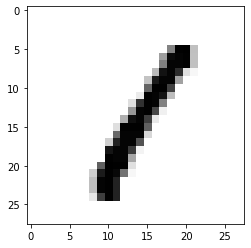

In [ ]:
digit = train_images[3]
import matplotlib.pyplot as plt
plt.imshow(digit, cmap=plt.cm.binary)
plt.show()

##Манипулирование тензорами с помощью Numpy

Операция выбора конкретного элемента в тензоре называется ***получением среза тензора***.

Следующий пример извлекает цифры с 10-й до 100-й и помещает их в массив, имеющий форму (90, 28, 28):

In [ ]:
my_slice = train_images[10:100]
print(my_slice.shape)

(90, 28, 28)


Это эквивалентно более подробной форме записи, в которой определяются начальный и конечный индексы среза для каждой оси тензора. Обратите внимание,
что : эквивалентно выбору всех элементов на оси:

In [ ]:
my_slice = train_images[10:100, :, :]
my_slice.shape

(90, 28, 28)

In [ ]:
my_slice = train_images[10:100, 0:28, 0:28]
my_slice.shape

(90, 28, 28)

В общем случае можно получить срез между любыми двумя индексами по каждой
оси тензора. Например, вот как можно выбрать пикселы из области 14 × 14 в правом
нижнем углу каждого изображения:

In [ ]:
my_slice = train_images[:, 14:, 14:]

Допускается использовать и отрицательные индексы. Так же как отрицательные
индексы в списках на Python, они будут откладываться от конца текущей оси.
Например, вот так можно обрезать все изображения, оставив только квадрат
14 × 14 пикселов в центре:

In [ ]:
my_slice = train_images[:, 7:-7, 7:-7]

## Пакеты данных

В общем случае первая ось во всех тензорах
будет *осью образцов* (иногда ее называют *измерением образцов*). В примере MNIST
образцы — это изображения цифр.

Кроме того, модели глубокого обучения не обрабатывают весь набор данных целиком; они разбивают его на небольшие пакеты. Вот один
пакет из примера с изображениями цифр MNIST, имеющий размер 128:

In [ ]:
batch = train_images[:128]

А вот следующий пакет:

In [ ]:
batch = train_images[128:256]

А вот n-й пакет:

In [ ]:
n = 10
batch = train_images[128 * n:128 * (n + 1)]

При рассмотрении таких пакетных тензоров первую ось (ось с индексом 0) называют осью пакетов, или измерением пакетов. Эта терминология часто будет
встречаться вам при работе с Keras и другими библиотеками глубокого обучения.

## Практические примеры тензоров с данными

Данные, которыми вам придется манипулировать, почти всегда будут относиться к одной из следующих категорий:
* *векторные данные* — двумерные тензоры с формой (образцы, признаки);
* *временные ряды или последовательности* — трехмерные тензоры с формой (образцы, метки_времени, признаки);
* *изображения* — четырехмерные тензоры с формой (образцы, высота, ширина,
цвет) или с формой (образцы, цвет, высота, ширина);
* *видео* — пятимерные тензоры с формой (образцы, кадры, высота, ширина, цвет)
или с формой (образцы, кадры, цвет, высота, ширина).

## Векторные данные

Наиболее часто встречающаяся форма данных. В таких наборах каждый образец
может быть представлен вектором, а пакет, соответственно, двумерным тензором
(то есть массивом векторов), где первая ось — это ось образцов, а вторая — ось признаков.
Рассмотрим два примера.
* Актуарный набор данных с информацией о людях, где для каждого человека
указываются возраст, почтовый индекс и доход. Каждый человек характеризуется
вектором с тремя значениями, соответственно, весь набор данных, описывающий
100 000 человек, можно сохранить в двумерном тензоре с формой (100000, 3).
* Коллекция текстовых документов, где каждый документ представлен количеством повторений каждого слова (из словаря с 20 000 наиболее употребительных слов). Каждый документ можно представить как вектор с 20 000 значений
(по одному счетчику на каждое слово из словаря), соответственно, весь набор
данных, описывающий 500 документов, можно сохранить в двумерном тензоре
с формой (500, 20000).

## Временные ряды или последовательности

Всякий раз, когда время (или понятие последовательной упорядоченности) играет
важную роль в ваших данных, такие данные предпочтительнее сохранять в трехмерном тензоре с явной осью времени. Каждый образец может быть представлен
как последовательность векторов (двумерных тензоров), а сам пакет данных — как
трехмерный тензор.

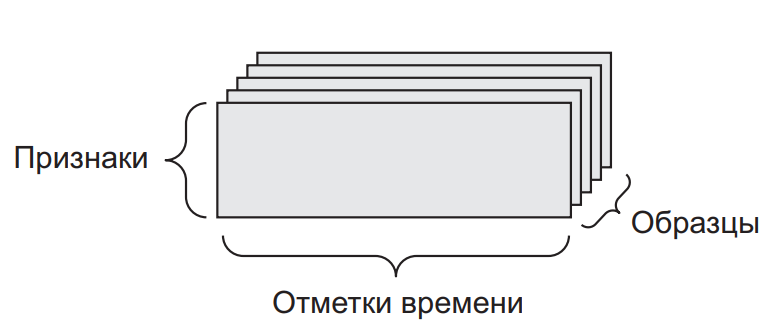

В соответствии с соглашениями, ось времени всегда является второй осью (осью
с индексом 1). Рассмотрим несколько примеров.
* Набор данных с ценами акций. Каждую минуту мы сохраняем текущую цену
акций, а также наибольшую и наименьшую цены за минувшую минуту. То есть
каждая минута представлена трехмерным вектором, весь торговый день — двумерным тензором с формой (390, 3) (где 390 — длительность торгового дня
в минутах), а данные за 250 дней — трехмерным тензором с формой (250, 390,
3). В данном случае каждый образец представляет данные за один торговый
день.
* Набор данных с твитами, где каждый твит кодируется последовательностью из
280 символов из алфавита со 128 уникальными символами. В данном случае
каждый символ можно закодировать как двоичный вектор со 128 элементами
(содержит нули во всех элементах, кроме элемента с индексом, соответствующим номеру символа в алфавите, в который записывается 1). При такой организации каждый твит можно представить как двумерный тензор с формой (280,
128), а набор с миллионом твитов — как тензор с формой (1000000, 280, 128).

## Изображения

Обычно изображения имеют три измерения: высоту, ширину и цвет. Даже при том,
что черно-белые изображения (как в наборе данных MNIST) имеют только один
канал цвета и могли бы храниться в двумерных тензорах, по соглашениям тензоры
с изображениями всегда имеют три измерения, где для черно-белых изображений
отводится только один канал цвета. Соответственно, пакет со 128 черно-белыми
изображениями, имеющими размер 256 × 256, можно сохранить в тензоре с формой
(128, 256, 256, 1), а пакет со 128 цветными изображениями — в тензоре с формой
(128, 256, 256, 3).

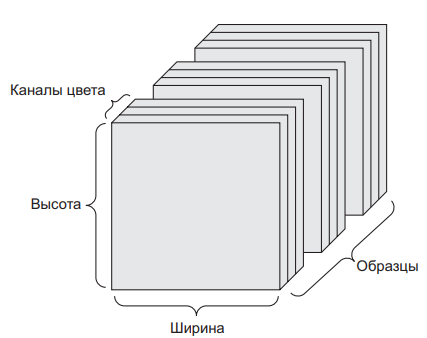

В отношении форм тензоров с изображениями существует два соглашения: соглашение *канал следует последним* (используется в TensorFlow) и соглашение
*канал следует первым* (используется в Theano). Фреймворк машинного обучения
TensorFlow, разработанный компанией Google, отводит для цвета последнюю ось:
(образцы, высота, ширина, цвет). А библиотека Theano отводит для цвета ось, следующую сразу за осью пакетов: (образцы, цвет, высота, ширина). Если следовать
соглашению, принятому в Theano, предыдущие примеры тензоров будут иметь
форму (128, 1, 256, 256) и (128, 3, 256, 256). Фреймворк Keras поддерживает
оба формата.

## Видео

Видеоданные — один из немногих типов данных, для хранения которых требуются
пятимерные тензоры. Видео можно представить как последовательность кадров, где
каждый кадр — цветное изображение. Каждый кадр можно сохранить в трехмерном
тензоре (высота, ширина, цвет), соответственно, их последовательность можно сохранить в четырехмерном тензоре (кадры, высота, ширина, цвет), а пакет разных видеороликов — в пятимерном тензоре с формой (образцы, кадры, высота, ширина, цвет).

Например, 60-секундный видеоклип с разрешением 144 × 256 и частотой 4 кадра
в секунду будет состоять из 240 кадров. Для сохранения пакета из четырех таких
клипов потребуется тензор с формой (4, 240, 144, 256, 3). То есть 106 168 320 значений! Если предположить, что dtype тензора определен как float32, тогда для
хранения каждого значения понадобится 32 бита, то есть для хранения всего тензора — 405 Мбайт. Видеоролики, с которыми вам придется столкнуться
в реальной жизни, намного легковеснее, потому что они не хранятся как коллекции
значений типа float32 и обычно подвергаются значительному сжатию (как, например, формат MPEG).

## Операции с тензорами

Тензоры можно складывать, перемножать и т. д.

В первом примере создали сеть, наложив друг на друга два слоя Dense.
В библиотеке Keras экземпляр слоя выглядит так:

In [ ]:
import keras
keras.layers.Dense(512, activation='relu')

Этот слой можно интерпретировать как функцию, которая принимает двумерный
тензор и возвращает другой двумерный тензор — новое представление исходного
тензора. В данном случае функция имеет следующий вид (где W — это двумерный
тензор, а b — вектор, оба значения являются атрибутами слоя):

In [ ]:
output = relu(dot(W, input) + b)

NameError: ignored

Здесь у нас имеется три операции с тензорами: скалярное
произведение (dot) исходного тензора input и тензора с именем W; сложение (+)
получившегося двумерного тензора и вектора b; и, наконец, операция relu. relu(x)
эквивалентна операции max(x, 0).

## Поэлементные операции

Операция relu и сложение — это *поэлементные операции*: операции, которые применяются к каждому элементу в тензоре по отдельности. Для
реализации поэлементных операций на Python можно использовать цикл for, как
в следующем примере реализации операции relu:

In [ ]:
def naive_relu(x):
  assert len(x.shape) == 2 # проверяем размерность
  x = x.copy()
  for i in range(x.shape[0]): n
    for j in range(x.shape[1]):
      x[i, j] = max(x[i, j], 0)
  return x

Точно так же реализуется сложение:

In [ ]:
def naive_add(x, y):
  assert len(x.shape) == 2
  assert x.shape == y.shape #Убедиться, что x и y — двумерные тензоры Numpy
  x = x.copy()
  for i in range(x.shape[0]):
    for j in range(x.shape[1]):
      x[i, j] += y[i, j]
  return x

Следуя тому же принципу, можно реализовать поэлементное умножение, вычитание и т. д.

При работе с массивами Numpy можно пользоваться уже готовыми, оптимизированными реализациями этих операций, доступными в виде функций из пакета
Numpy, которые сами делегируют основную работу реализациям базовых подпрограмм линейной алгебры.

Иными словами, при использовании Numpy поэлементные операции можно записывать, как показано ниже, и они будут выполняться почти мгновенно:

In [ ]:
import numpy as np
z = x + y #Поэлементное сложение
z = np.maximum(z, 0.) #Поэлементная операция relu

## Расширение


Что происходит при сложении, когда
формы складываемых тензоров различаются?

Когда это возможно и не вызывает неоднозначности, меньший тензор расширяется
так, чтобы его новая форма соответствовала форме большего тензора. Расширение
выполняется в два этапа:


1.   В меньший тензор добавляются оси (называются *осями расширения*), чтобы
значение его атрибута ndim соответствовало значению этого же атрибута большего тензора.
2.   Меньший тензор копируется в эти новые оси до полного совпадения с формой
большего тензора.



Рассмотрим конкретный пример. Пусть имеются тензоры X с формой (32, 10)
и y с формой (10,). Чтобы привести их в соответствие, сначала нужно добавить
в тензор y первую пустую ось, чтобы он приобрел форму (1, 10), а затем скопировать вторую ось 32 раза, чтобы в результате получился тензор Y с формой (32, 10),
где Y[i, :] == y для i в диапазоне range(0, 32). После этого можно сложить X и Y,
которые имеют одинаковую форму.

В фактической реализации новый двумерный тензор, конечно же, не создается,
потому что это было бы неэффективно. Операция копирования выполняется чисто
виртуально: она происходит на алгоритмическом уровне, а не в памяти. Но такое
представление с копированием вектора для новой оси является полезной мысленной моделью. Вот как могла бы выглядеть наивная реализация:

In [ ]:
def naive_add_matrix_and_vector(x, y):
  assert len(x.shape) == 2. #Убедиться, что x — двумерный тензор Numpy.
  assert len(y.shape) == 1. #Убедиться, что y — вектор Numpy.
  assert x.shape[1] == y.shape[0]
  x = x.copy()
  for i in range(x.shape[0]):
    for j in range(x.shape[1]):
      x[i, j] += y[j]
  return x

Прием расширения в общем случае можно применять в поэлементных операциях
с двумя тензорами, если один тензор имеет форму (a, b, ... n, n + 1, ... m), а другой — форму (n, n + 1, ... m). В этом случае при расширении будут добавлены оси
до n - 1.

Следующий пример применяет поэлементную операцию maximum к двум тензорам
с разными формами посредством расширения:

In [ ]:
import numpy as np
x = np.random.random((64, 3, 32, 10)) #x — тензор случайных чисел, имеющий форму (64, 3, 32, 10)
y = np.random.random((32, 10)) #y — тензор случайных чисел, имеющий форму (32, 10)
z = np.maximum(x, y) #Получившийся тензор z имеет форму (64, 3, 32, 10) аналогично x
z.shape

## Скалярное произведение тензоров

Скалярное произведение, также иногда называемое тензорным произведением (не
путайте с поэлементным произведением), — наиболее общая и наиболее полезная операция с тензорами. В отличие от поэлементных операций, она объединяет элементы из исходных тензоров.

Поэлементное произведение в Numpy, Keras, Theano и TensorFlow выполняется
с помощью оператора *. Операция скалярного произведения в TensorFlow имеет
иной синтаксис, но в Numpy и Keras используется простой оператор dot:

In [ ]:
import numpy as np
z = np.dot(x, y)

В математике скалярное произведение обозначается точкой (.):

z = x . y

Что же делает операция скалярного произведения? Для начала разберемся со скалярным произведением двух векторов, x и y:

In [ ]:
def naive_vector_dot(x, y):
  assert len(x.shape) == 1
  assert len(y.shape) == 1
  assert x.shape[0] == y.shape[0]

  z = 0.
  for i in range(x.shape[0]):
    z += x[i] * y[i]
  return z

Обратите внимание, что в результате скалярного произведения двух векторов
получается скаляр и в операции могут участвовать только векторы с одинаковым
количеством элементов.

Также есть возможность получить скалярное произведение матрицы x на вектор y,
являющееся вектором, элементы которого — скалярные произведения строк x на y.
Вот как реализуется эта операция:

In [ ]:
get import numpy as np
def naive_matrix_vector_dot(x, y):
  assert len(x.shape) == 2 #Убедиться, что x — матрица Numpy
  assert len(y.shape) == 1 #Убедиться, что y — вектор Numpy
  assert x.shape[1] == y.shape[0] #Первое измерение x должно совпадать с нулевым измерением y!
  z = np.zeros(x.shape[0]) #Эта операция вернет вектор с нулевыми элементами, имеющий ту же форму, что и y
  for i in range(x.shape[0]):
    for j in range(x.shape[1]):
      z[i] += x[i, j] * y[j]
  return z

Также можно было бы повторно использовать код, написанный прежде, подчеркнув
общность произведений матрицы на вектор и вектора на вектор:

In [ ]:
def naive_matrix_vector_dot(x, y):
  z = np.zeros(x.shape[0])
  for i in range(x.shape[0]):
    z[i] = naive_vector_dot(x[i, :], y)
  return z

Обратите внимание, что, если один из двух тензоров имеет ndim больше 1, скалярное произведение перестает быть симметричной операцией, то есть результат
dot(x, y) не совпадает с результатом dot(y, x).

Разумеется, скалярное произведение можно распространить на тензоры с произвольным количеством осей. Наиболее часто на практике применяется скалярное
произведение двух матриц. Получить скалярное произведение двух матриц, x и y
(dot(x, y)), можно, только если x.shape[1] == y.shape[0]. В результате получится матрица с формой (x.shape[0], y.shape[1]), элементами которой являются
скалярные произведения строк x на столбцы y. Вот как могла бы выглядеть простейшая реализация:

In [ ]:
def naive_matrix_dot(x, y):
 assert len(x.shape) == 2
 assert len(y.shape) == 2 #Убедиться, что x и y — матрицы Numpy
 assert x.shape[1] == y.shape[0] #Первое измерение x должно совпадать с нулевым измерением y!
 z = np.zeros((x.shape[0], y.shape[1])) #Эта операция вернет матрицу заданной формы с нулевыми элементами
 for i in range(x.shape[0]): #Обход строк в x...
  for j in range(y.shape[1]): #... и столбцов в y
    row_x = x[i, :]
    column_y = y[:, j]
    z[i, j] = naive_vector_dot(row_x, column_y)
 return z

Чтобы было понятнее, как определяется совместимость форм матриц для скалярного произведения, представьте входные и выходной тензоры, как показано на
рисунке.

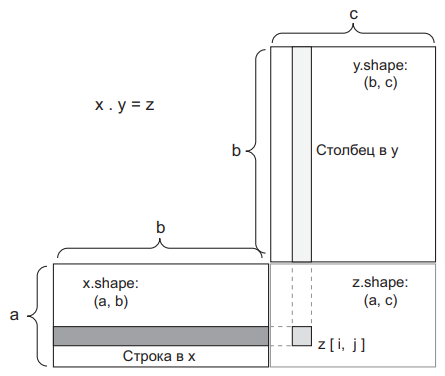

Матрицы x, y и z изображены на рисунке в виде прямоугольников (буквально — таблицы элементов). Количество строк в x и столбцов в y должно совпадать, из чего
следует, что ширина x должна совпадать с высотой y.

В общем случае скалярное произведение тензоров с большим числом измерений
выполняется в соответствии с теми же правилами совместимости форм, как описывалось выше для случая двумерных матриц:

(a, b, c, d) . (d,) -> (a, b, c)

(a, b, c, d) . (d, e) -> (a, b, c, e)

и т. д.

## Изменение формы тензора

Эта операция не используется в слоях Dense нашей нейронной
сети, но мы использовали ее, когда готовили исходные данные для передачи в сеть:

In [ ]:
train_images = train_images.reshape((60000, 28 * 28))

Изменение формы тензора предполагает такое переупорядочение строк и столбцов,
чтобы привести его форму к заданной. Разумеется, тензор с измененной формой
имеет такое же количество элементов, что и исходный тензор. Чтобы было понятнее, рассмотрим несколько простых примеров:

In [ ]:
 x = np.array([[0., 1.],
               [2., 3.],
               [4., 5.]])
 print(x.shape)

In [ ]:
x = x.reshape((6, 1))
x

In [ ]:
x = x.reshape((2, 3))
x

Особый случай изменения формы, который часто встречается в практике, — это
транспонирование. *Транспонирование* — это такое преобразование матрицы, когда
строки становятся столбцами, а столбцы — строками, то есть x[i, :] превращается
в x[:, i]:

In [ ]:
x = np.zeros((300, 20))
x = np.transpose(x)
print(x.shape)

## Геометрическая интерпретация операций с тензорами

Поскольку содержимое тензоров можно интерпретировать как координаты точек
в некотором геометрическом пространстве, все операции с тензорами имеют геометрическую интерпретацию. Возьмем для примера операцию сложения. Пусть
имеется следующий вектор:

A = [0.5, 1]

Он определяет направление в двумерном пространстве (рис. 1). Векторы принято
изображать в виде стрелок, соединяющих начало координат с заданной точкой, как
показано на рис. 2.

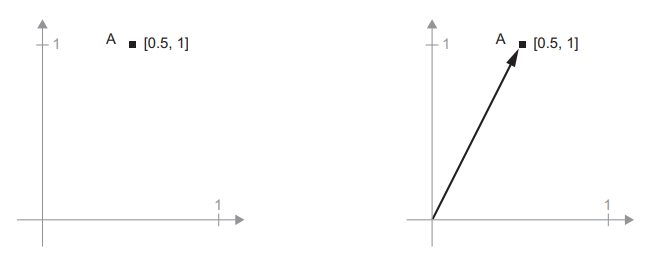

Добавим новый вектор B = [1, 0.25] и сложим его с предыдущим. Чтобы получить
результирующий вектор, представляющий сумму двух исходных векторов, достаточно перенести начало одного вектора в конец другого.

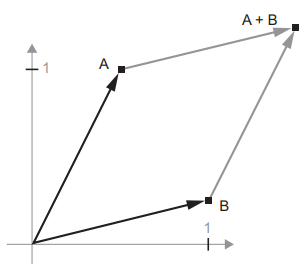

## Геометрическая интерпретация глубокого обучения

Нейронную сеть можно интерпретировать как сложное геометрическое преобразование в многомерном пространстве,
реализованное в виде последовательности простых шагов.

Иногда полезно представить следующий мысленный образ в трехмерном пространстве. Вообразите два листа цветной бумаги: один лист красного цвета и другой —
синего. Положите их друг на друга. Теперь скомкайте их в маленький комок. Этот
мятый бумажный комок — ваши входные данные, а каждый лист бумаги — класс
данных в задаче классификации. Суть работы нейронной сети (или любой другой
модели машинного обучения) заключается в таком преобразовании комка бумаги,
чтобы разгладить его и сделать два класса снова ясно различимыми. В глубоком
обучении это реализуется как последовательность простых преобразований в трехмерном пространстве, как если бы вы производили манипуляции пальцами с бумажным комком, по одному движению за раз.

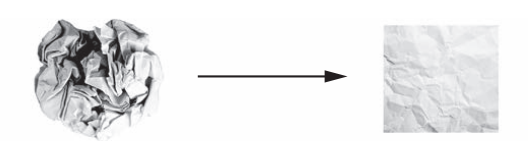

Разглаживание комка бумаги — вот что делает машинное обучение: поиск ясных
представлений для сложных перемешанных данных. На данный момент у вас
должно сложиться достаточно полное понимание, почему глубокое обучение преуспевает в этом: оно использует подход последовательного разложения сложных
геометрических преобразований в длинную цепь простых почти так же, как поступает человек, разглаживая комок бумаги. Каждый слой в глубоком обучении
применяет преобразование, которое немного распутывает данные, а использование
множества слоев позволяет распутывать очень сложные данные.

# Механизм нейронных сетей: оптимизация на основе градиента

Каждый слой нейронной сети из
первого примера преобразует данные следующим образом:

In [ ]:
output = relu(dot(W, input) + b)

В этом выражении W и b — тензоры, являющиеся атрибутами слоя. Они называются
весами, или обучаемыми параметрами слоя (атрибуты kernel - ядро и bias - смещение соответственно). Эти веса содержат информацию, извлеченную сетью из обучающих данных.

Первоначально эти весовые матрицы заполняются небольшими случайными
значениями (этот шаг называется случайной инициализацией). Далее, на основе сигнала
обратной связи, происходит постепенная корректировка весов. Эта постепенная
корректировка, которая также называется обучением, составляет суть машинного
обучения.

Ниже перечислены шаги, выполняемые в так называемом цикле обучения, который
повторяется столько раз, сколько потребуется:
1. Извлекается пакет обучающих экземпляров x и соответствующих целей y.
2. Сеть обрабатывает пакет x (этот шаг называется прямым проходом) и получает
пакет предсказаний y_pred.
3. Вычисляются потери сети на пакете, дающие оценку несовпадения между y_pred
и y.
4. Корректируются веса сети так, чтобы немного уменьшить потери на этом пакете.

В конечном итоге получается сеть, имеющая очень низкие потери на тренировочном наборе данных: малое несовпадение предсказаний y_pred с ожидаемыми
целями y. Сеть «научилась» отображать входные данные в правильные конечные
значения. Со стороны все это может походить на волшебство, однако если разобрать процесс на мелкие шаги, он выглядит очень просто.

## Что такое производная?

Рассмотрим непрерывную гладкую функцию f(x) = y, отображающую вещественное число x в новое вещественное число y. Поскольку функция непрерывна,
небольшое изменение x может дать в результате только небольшое изменение
y — это вытекает из понятия непрерывности. Допустим, вы увеличили x на маленькую величину epsilon_x: в результате y изменилось на маленькую величину
epsilon_y:

f(x + epsilon_x) = y + epsilon_y

Кроме того, так как функция *гладкая* (ее кривая не имеет острых углов), когда
epsilon_x — достаточно маленькая величина отклонения, в окрестностях точки p
можно аппроксимировать f линейной функцией с наклоном a, такой, что epsilon_y
станет равным a * epsilon_x:

f(x + epsilon_x) = y + a * epsilon_x

Очевидно, что такая линейная аппроксимация действительна, только когда x располагается достаточно близко к точке p.

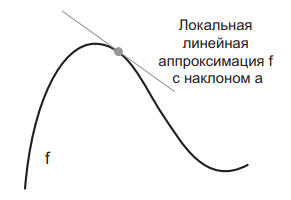

Наклон a называется *производной* f в точке p. Если a имеет отрицательное значение,
значит, небольшое изменение x в окрестностях p приведет к уменьшению f(x); а если положительное, небольшое изменение x приведет к увеличению f(x). Кроме того, абсолютное значение a (величина производной)
сообщает, насколько большим будет это увеличение или уменьшение.

Для любой дифференцируемой функции f(x) (под дифференцируемостью подразумевается «имеет производную»: например, гладкие непрерывные функции
могут иметь производную) существует такая производная функция f'(x), которая
отображает значения x в наклон локальной линейной аппроксимации в точках f.
Например, производной от cos(x) является -sin(x), производной от f(x) = a * x является f'(x) = a и т. д.

Если вы пытаетесь изменить x на величину epsilon_x, чтобы минимизировать
f(x), и знаете производную от f, можете считать, что эту задачу вы уже решили:
производная полностью описывает поведение f(x) с изменением x. Чтобы уменьшить значение f(x), достаточно сместить x в направлении, противоположном
производной.

## Производная операций с тензорами: градиент

Градиент — это производная операции с тензором, обобщение понятия производной на функции с многомерными входными данными, то есть на функции, принимающие на входе тензоры.

Рассмотрим входной вектор x, матрицу W, цель y и функцию потерь loss. Вы можете
с помощью W вычислить приближение к цели y_pred и определить потери или несоответствие, между кандидатом y_pred и целью y:

In [ ]:
y_pred = dot(W, x)
loss_value = loss(y_pred, y)

Если входные данные x и y зафиксированы, тогда это можно интерпретировать как
функцию, отображающую значения W в значения потерь:

In [ ]:
loss_value = f(W)

Допустим, что W0 — текущее значение W. Тогда производной функции f в точке W0 будет тензор gradient(f)(W0) с той же формой, что и W, в котором каждый элемент gradient(f) (W0)[i, j] определяет направление и величину изменения
в loss_value, наблюдаемого при изменении W0[i, j]. Тензор gradient(f)(W0) — это
градиент функции f(W) = loss_value в W0.

Выше вы видели, что производную функции f(x) единственного аргумента можно
интерпретировать как наклон кривой f. Аналогично gradient(f)(W0) можно интерпретировать как тензор, описывающий кривизну f(W) в окрестностях W0.

Соответственно, как и в случае с функцией f(x), значение которой можно
уменьшить, немного сместив x в направлении, противоположном производной,
функцию f(W) тензора также можно уменьшить, сместив W в направлении, противоположном градиенту: например, W1 = W0 - step * gradient(f)(W0) (где step —
небольшой по величине множитель). Это означает, что для снижения нужно идти
против кривизны. Обратите внимание: множитель step необходим, потому что
gradient(f)(W0) лишь аппроксимирует кривизну в окрестностях W0, поэтому очень
нежелательно уходить слишком далеко от W0.

##  Стохастический градиентный спуск

Теоретически минимум дифференцируемой функции можно найти аналитически.
Как известно, минимум функции — это точка, где производная равна 0. То есть остается только найти все точки, где производная обращается в 0, и выяснить, в какой
из этих точек функция имеет наименьшее значение.

Применительно к нейронным сетям это означает аналитический поиск комбинации значений весов, при которых функция потерь будет иметь наименьшее
значение. Этого можно добиться, решив уравнение gradient(f)(W) = 0 для W. Это
полиномиальное уравнение с N переменными, где N — количество весов в сети.
Решить уравнение для случая N = 2 или N = 3 не составляет труда, но превращается в практически неразрешимую задачу для нейронных сетей, в которых
количество параметров редко бывает меньше нескольких тысяч и часто достигает
нескольких десятков миллионов.

Поэтому на практике используется алгоритм из четырех шагов, представленный
в начале этого раздела: вы можете понемногу изменять параметры, опираясь на
текущие значения потерь в случайном пакете данных. Поскольку функция дифференцируема, можно вычислить ее градиент, который позволяет эффективно реализовать шаг 4. Если веса изменить в направлении, противоположном градиенту,
потери с каждым циклом будут понемногу уменьшаться:
1. Извлекается пакет обучающих экземпляров x и соответствующих целей y.
2. Сеть обрабатывает пакет x и получает пакет предсказаний y_pred.
3. Вычисляются потери сети на пакете, дающие оценку несовпадения между y_pred
и y.
4. Вычисляется градиент потерь для параметров сети (*обратный проход*).
5. Параметры корректируются на небольшую величину в направлении, противоположном градиенту, например W -= step * gradient, и тем самым снижаются
потери.

Термин «стохастический» отражает тот факт, что каждый пакет данных выбирается
случайно (в науке слово «стохастический» считается синонимом слова «случайный»).

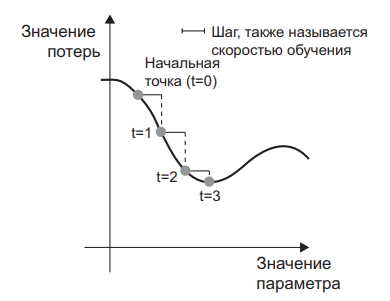

Рисунок иллюстрирует происходящее на примере одномерных данных,
когда сеть имеет только один параметр и в вашем распоряжении имеется только
один обучающий образец.

Как можно заметить, выбор разумной величины шага step имеет большое значение. Если выбрать его слишком маленьким, спуск потребует большого количества
итераций и может застрять в локальном минимуме. Если шаг будет слишком
большим, ваши корректировки могут приобретать нецеленаправленный характер
и приводить в случайные точки на кривой.

Обратите внимание, что вариант алгоритма mini-batch SGD, изображенный на
рисунке, в каждой итерации использует единственный образец и цель, а не весь
пакет данных. Фактически это истинный SGD (а не mini-batch SGD). Однако можно пойти другим путем и использовать на каждом шаге все доступные данные. Эта
версия алгоритма называется пакетным стохастическим градиентным спуском
(batch SGD). Каждое изменение в этом случае будет более точным, но более затратным. Эффективным компромиссом между этими двумя крайностями является
использование небольших пакетов.

На рисунке изображен градиентный спуск в одномерном пространстве параметров,
на практике вы будете использовать градиентный спуск в пространствах с намного
большим количеством измерений: каждый весовой коэффициент в нейронной сети — это независимое измерение в пространстве, и их может быть десятки тысяч
или даже миллионы.

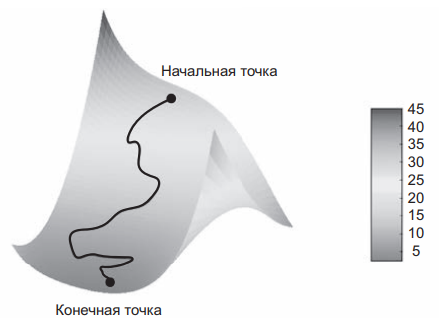

Чтобы получить представление о поверхностях потерь, представьте градиентный спуск по двумерной поверхности, как показано на рисунке.
Но имейте в виду, что вам не удастся мысленно представить фактический процесс
обучения нейронной сети — нельзя представить 1 000 000-мерное пространство
более или менее осмысленным способом. Поэтому всегда помните, что представление, полученное на таких моделях с небольшим количеством измерений, может
быть не всегда точным на практике. В прошлом это часто приводило к ошибкам
исследователей глубокого обучения.

Существует также множество вариантов стохастического градиентного спуска,
которые отличаются тем, что при вычислении следующих приращений весов
принимают в учет не только текущие значения градиентов, но и предыдущие
приращения. Примерами могут служить такие алгоритмы, как SGD с импульсом,
Adagrad, RMSProp и некоторые другие. Эти варианты известны как методы оптимизации, или оптимизаторы. В частности, внимания заслуживает идея импульса,
которая используется во многих этих вариантах. Импульс вводится для решения
двух проблем SGD: невысокой скорости сходимости и попадания в локальный
минимум. Взгляните на рисунок, на котором изображена кривая функции потерь
для параметра сети.

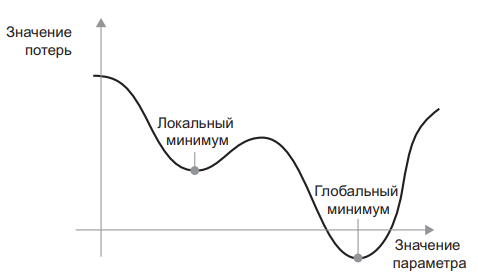

Как видите, для значения данного параметра имеется *локальный минимум*: движение из этой точки влево или вправо повлечет увеличение потери. Если корректировка рассматриваемого параметра осуществляется методом градиентного
спуска с маленьким шагом обучения, тогда процесс оптимизации может застрять
в локальном минимуме, не найдя пути к глобальному минимуму.

Таких проблем можно избежать, если использовать идею импульса, заимствованную из физики. Вообразите, что процесс оптимизации — это маленький шарик, катящийся вниз по кривой потерь. Если шарик имеет достаточно высокий импульс,
он не застрянет в мелком овраге и окажется в глобальном минимуме. Импульс
реализуется путем перемещения шарика на каждом шаге, исходя не только из
текущей величины наклона (текущего ускорения), но также из текущей скорости
(набранной в результате действия силы ускорения на предыдущем шаге). На практике это означает, что приращение параметра w определяется не только по текущему
значению градиента, но также по величине предыдущего приращения параметра,
как показано в следующей упрощенной реализации:

In [ ]:
past_velocity = 0.
momentum = 0.1 #Постоянное значение импульса
while loss > 0.01: #Цикл оптимизации
  w, loss, gradient = get_current_parameters()
  velocity = past_velocity * momentum + learning_rate * gradient
  w = w + momentum * velocity - learning_rate * gradient
  past_velocity = velocity
  update_parameter(w)

##  Объединение производных: алгоритм обратного распространения ошибки

В предыдущем алгоритме мы произвольно предположили, что, если функция дифференцируема, мы можем явно вычислить ее производную. На практике функция
нейронной сети состоит из множества последовательных операций с тензорами,
объединенных в одну цепочку, каждая из которых имеет простую, известную производную. Например, пусть есть сеть f, состоящая из трех операций с тензорами a,
b и c и весовыми матрицами W1, W2 и W3:

f(W1, W2, W3) = a(W1, b(W2, c(W3)))

Формула сообщает нам, что такую цепочку функций можно получить с использованием следующего тождества, которое называется *цепным правилом*: f(g(x)) = f'(g(x)) * g'(x). Применение цепного правила к вычислению значений градиента нейронной сети приводит к алгоритму, который называется *обратным распространением ошибки* (Backpropagation), или *обратным дифференцированием*.
Обратное распространение начинается с конечного значения потери и движется
в обратном направлении, от верхних слоев к нижним, применяя цепное правило
для вычисления вклада каждого параметра в значение потери.

В настоящее время и еще на протяжении многих лет в будущем люди создают
и будут создавать сети на основе современных фреймворков с поддержкой символического дифференцирования, таких как TensorFlow. Это означает, что для данной
цепочки операций с известной производной они могут вычислять функцию градиента для цепочки (применяя цепное правило), которая отображает значения
параметров сети в значения градиента. При наличии такой функции обратный
проход сводится к вызову этой функции градиента. Благодаря символическому
дифференцированию вам никогда не придется заниматься реализацией алгоритма
обратного распространения ошибки вручную. Все, что вам нужно, — это хорошее
понимание принципа работы оптимизации на основе градиента.

## Оглядываясь на первый пример

Теперь вы должны неплохо представлять себе, что
происходит в недрах нейронной сети. Давайте вернемся назад, к первому примеру,
и рассмотрим каждую его часть в свете новых знаний, полученных в трех предыдущих разделах.

Вот наши входные данные:

In [ ]:
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

train_images = train_images.reshape((60000, 28 * 28))
train_images = train_images.astype('float32') / 255

test_images = test_images.reshape((10000, 28 * 28))
test_images = test_images.astype('float32') / 255

Теперь вы уже знаете, что входные данные типа float32 хранятся в тензорах Numpy,
имеющих форму (60000, 784) (обучающие данные) и (10000, 784) (контрольные
данные) соответственно.

Вот наша сеть:

In [ ]:
network = models.Sequential()
network.add(layers.Dense(512, activation='relu', input_shape=(28 * 28,)))
network.add(layers.Dense(10, activation='softmax'))

Сейчас вы уже знаете, что эта сеть состоит из цепочки двух слоев Dense, каждый из
которых применяет к входным данным несколько простых операций с тензорами, и что эти операции вовлекают весовые тензоры. Весовые тензоры, являющиеся
атрибутами слоев, — это место, где запоминаются знания, накопленные сетью.

Вот как выглядел этап компиляции:

In [ ]:
network.compile(optimizer='rmsprop',
                loss='categorical_crossentropy',
                metrics=['accuracy'])

Сейчас вы уже понимаете, что categorical_crossentropy — это функция потерь,
которая используется в качестве сигнала обратной связи для обучения весовых
тензоров и которую этап обучения стремится свести к минимуму. Вы также знаете,
что снижение потерь достигается за счет применения алгоритма стохастического
градиентного спуска на небольших пакетах. Точные правила, управляющие конкретным применением градиентного спуска, определяются оптимизатором rmsprop,
который передается в первом аргументе.

Наконец, вот как выглядел цикл обучения:

In [ ]:
network.fit(train_images, train_labels, epochs=5, batch_size=128)

Теперь вы знаете, что происходит в вызове fit: сеть начинает перебирать обучающие данные мини-пакетами по 128 образцов и выполняет 5 итераций (каждая
итерация по всем обучающим данным называется эпохой). Для каждого мини-пакета сеть вычисляет градиенты весов с учетом потерь в пакете и изменяет значения
весов в соответствующем направлении. В течение пяти эпох сеть выполнит 2345 изменений градиента (по 469 на эпоху), после чего потери сети окажутся достаточно
низкими, чтобы эта сеть смогла классифицировать рукописные цифры с высокой
точностью.

Теперь вы знаете большую часть из того, что нужно знать о нейронных сетях.

#Краткие итоги

* Обучение означает поиск комбинации параметров модели, минимизирующих
функцию потерь для данного набора обучающих данных и соответствующих
им целей.
* Обучение происходит путем извлечения пакетов случайных образцов данных
и их целей и вычисления градиента параметров сети с учетом потерь в пакете.
Затем параметры сети немного смещаются (величина смещения определяется
скоростью обучения) в направлении, противоположном направлению градиента.
* Весь процесс обучения становится возможным благодаря тому обстоятельству, что нейронные сети являются цепочками дифференцируемых операций
с тензорами и, следовательно, позволяют применять цепное правило для вывода функции градиента, отображающей текущие параметры и текущий пакет
данных в значение градиента.
* В последующих главах вам часто будут встречаться два ключевых понятия —
функции потерь и оптимизаторы. Они должны быть определены до передачи
данных в сеть.
* Функция потерь — это величина, которую требуется свести к минимуму в ходе
обучения, поэтому она должна представлять собой меру успеха для решаемой
вами задачи.
* Оптимизатор определяет точный способ использования градиента потерь для
изменения параметров: например, это может быть оптимизатор RMSProp, реализующий градиентный спуск с импульсом, и др.

#Задание


Формула стохастического градиентного спуска

$\omega_{n+1} = \omega_n - \alpha \nabla loss$

$loss = (x_n \cdot \omega_n - y_n)^2 = (\hat{y} - y)^2$

где

$\alpha$ - это градиентный шаг и $\omega$ - это весы.

1. Вычислить и сохранить в массив значения функции, заданной с помощью ряда Тейлора, на интервале от x_нач до x_кон с шагом dx с точностью ϵ=0.0001. Входные данные: x_data $= [x_{нач}, ..., x_{кон}]$

2. Используйте метод стохастического градиентного спуска, чтобы получить оптимальные параметры весов для ряда Тейлора. Сравните полученное решение с помощью оптимальных весов с точным решением.

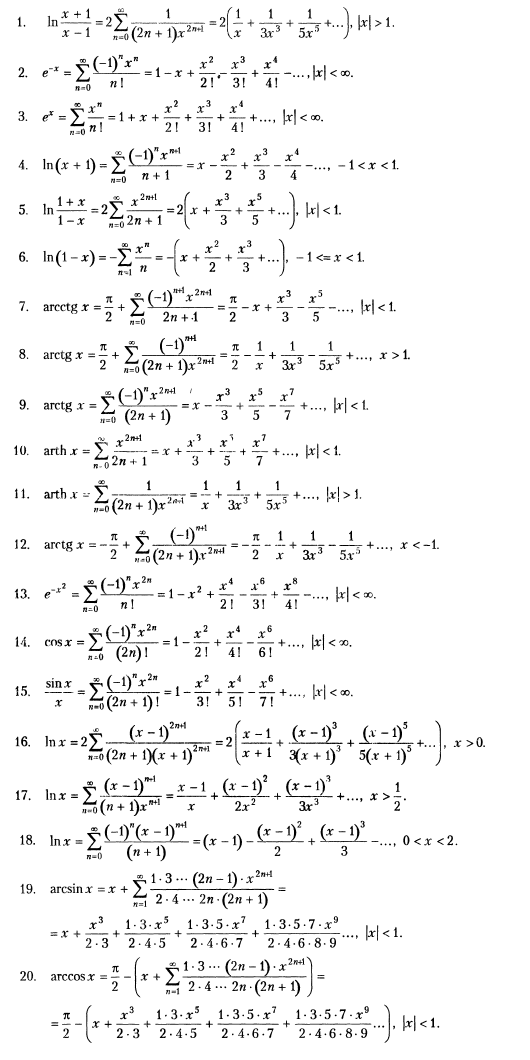